# ICT-36f — F-Lens × specparam : l'instrument spectral du papier LSD sur la série

**Navigation** : [Index ICT-Series](README.md) | [<< ICT-36e](ICT-36e-FLens-SNR-Python.ipynb) | [>> ICT-37](ICT-37-FLens-BeliefState-Python.ipynb)

**Objectifs** : (1) monter l'instrument que le papier LSD (Subramani et al. 2026, bioRxiv 10.64898/2026.01.28.702361) utilise pour ses hypothèses H1/H2 — la paramétrisation spectrale FOOOF (apériodique 1/f + pics gaussiens, 1–120 Hz, au plus 5 pics) — et le **sanity-checker** sur des spectres simulés où la vérité terrain est exacte ; (2) vérifier chiffrément que l'instrument récupère les deux gestes du papier : le décalage des fréquences pic (H1 : alpha +2 Hz, beta +5 Hz) et la suppression de puissance oscillatoire « genuine » une fois l'apériodique retirée (H2) ; (3) poser la question que la série attend depuis 36c — **la pente apériodique est-elle un compteur croissant du nombre de facteurs latents k ?** Les quatre instruments mesurés jusqu'ici (PR, NC@95, HFD, LZC) décroissent tous avec k ; l'exposant spectral est le cinquième candidat.

**Échos de la série** : le terrain GHMM à k variable est celui d'[ICT-36c](ICT-36c-FLens-HiguchiBridge-Python.ipynb) (pont F-Lens × Higuchi) ; la question « quel instrument suit k ? » y a été tranchée par la mesure (aucun des quatre ne croît) ; [ICT-36d](ICT-36d-FLens-DecorrelationTemporelle-Python.ipynb) a montré qu'une HFD qui monte peut signifier une dé-corrélation temporelle, pas plus de facteurs ; [ICT-36e](ICT-36e-FLens-SNR-Python.ipynb) a fixé le plancher de bruit sous lequel la géométrie factorielle devient illisible. Ce carnet ajoute la **jambe spectrale** : ce que la forme 1/f du spectre dit — et ne dit pas — de la structure factorielle.

**Prérequis** : kernel `ict-py313` (numpy, scipy, matplotlib, `fooof` 1.1, `antropy` ; install locale documentée en section 8) ; aucun appel réseau, aucune donnée réelle, ~1 min CPU.


> **Statut épistémique** — **Sans verdict à ce jour** : ce carnet n'a pas encore de ligne dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md), donc aucune solidité n'est revendiquée ici. Ce qu'il mesure est reproductible depuis ses cellules ; ce n'est pas un acquis de la série.


## 1. Mise en place

Les imports et les constantes. Contrairement à 36c/36e, ce carnet **n'importe aucun organe `ict/`** : son instrument est le package `fooof` lui-même (l'outil du papier, réglé aux valeurs de l'article — apériodique fixé, au plus 5 pics), et le terrain GHMM de la section 5 est redéfini fidèlement à 36c. La grille spectrale est celle du protocole MEG du papier : 1–120 Hz, résolution 0,5 Hz (epochs de 2 s échantillonnées à 1200 Hz).


In [1]:
import warnings

import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
import antropy as ent

# fooof 1.1 force l'affichage de son propre avertissement de depreciation
# (`simplefilter('always')` dans son __init__) : un filtre pose avant l'import
# ne le retient pas, et l'avertissement imprime le chemin absolu du paquet de
# l'environnement d'execution. Le charger sous un enregistreur detourne
# l'affichage vers une liste -- l'avertissement est recu, pas publie dans une
# sortie committee. Le choix de fooof plutot que specparam est celui du papier.
with warnings.catch_warnings(record=True) as _avertissement_fooof:
    warnings.simplefilter("always")
    import fooof
    from fooof import FOOOF

print("fooof", fooof.__version__, "| antropy", ent.__version__, "| numpy", np.__version__)

# Grille spectrale du papier : 1-120 Hz, resolution 0.5 Hz (epochs 2 s a 1200 Hz).
FREQS = np.arange(1.0, 120.5, 0.5)
FREQ_RANGE = (1.0, 120.0)

# Reglages du papier (Subramani et al. 2026) : aperiodique fixe, au plus 5 pics.
APERIODIC_MODE = "fixed"
MAX_N_PEAKS = 5
PEAK_WIDTH_LIMITS = (1.0, 12.0)

# Conditions simulees, d'apres les effets rapports par le papier :
#   H1 -- pics decales vers le haut (alpha +2 Hz, beta +5 Hz) ;
#   H2 -- suppression de puissance oscillatoire theta->beta (amplitudes PW baissees) ;
#   1/f flattening -- exposant aperiodique qui baisse (2.0 -> 1.5), offset qui descend.
# Chaque pic : (frequence centrale Hz, amplitude log10, largeur Hz).
COND = {
    "pbo": dict(offset=0.0, exponent=2.0,
                peaks=[(10.0, 1.00, 2.0), (20.0, 0.55, 3.0)]),
    "lsd": dict(offset=-0.3, exponent=1.5,
                peaks=[(12.0, 0.70, 2.0), (25.0, 0.35, 3.0)]),
}

# Bandes du papier pour H2 (theta -> beta) + gamma (augmente apres retrait aperiodique).
BANDS = {"theta": (4.0, 8.0), "alpha": (8.0, 12.0),
         "beta": (12.0, 30.0), "gamma": (60.0, 90.0)}

SEEDS = [0, 1, 7, 42]          # multi-seed (>= 4, discipline maison)
K_GRID = [0, 1, 2, 3, 4, 5]    # terrain GHMM, comme ICT-36c
JITTER_DB = 0.01               # bruit de mesure du spectre moyen (log10)

fooof 1.1.1 | antropy 0.2.3 | numpy 2.5.4


## 2. L'instrument : FOOOF sur spectres simulés à vérité exacte

Le modèle génératif du papier est simple et additif en échelle log : une composante apériodique `offset − exponent × log₁₀(f)` plus des pics gaussiens. On le simule tel quel, avec un léger bruit de mesure, puis on demande à FOOOF de retrouver les paramètres. C'est le sanity check que le protocole de distillation appelle « reproduction FOOOF sur signaux simulés » : si l'instrument ne récupère pas la vérité terrain sur un spectre construit sur son propre modèle, aucune confiance n'est possible sur données réelles.


In [2]:
def make_psd(spec, rng, jitter_db=JITTER_DB):
    """PSD log-additive : aperiodique + pics gaussiens (modele FOOOF) + bruit de mesure."""
    # Composante aperiodique : droite de pente -exponent en log-log
    log_p = spec["offset"] - spec["exponent"] * np.log10(FREQS)
    # Pics oscillatoires : une gaussienne par pic, centree sur cf, de largeur bw
    for cf, pw, bw in spec["peaks"]:
        log_p = log_p + pw * np.exp(-0.5 * ((FREQS - cf) / bw) ** 2)
    # Bruit de mesure additif : ce que le fit doit absorber sans le confondre avec un pic
    log_p = log_p + jitter_db * rng.standard_normal(FREQS.shape)
    return 10.0 ** log_p


def fit_spec(psd):
    """Fit FOOOF aux reglages du papier, sur la plage 1-120 Hz."""
    # Reglages du papier : mode aperiodique et nombre maximal de pics fixes
    fm = FOOOF(aperiodic_mode=APERIODIC_MODE, max_n_peaks=MAX_N_PEAKS,
               peak_width_limits=PEAK_WIDTH_LIMITS, verbose=False)
    # La plage 1-120 Hz ecarte la derive basse frequence, non modelisable ici
    fm.fit(FREQS, psd, freq_range=FREQ_RANGE)
    return fm


def peaks_cf(fm, n):
    """CF des n pics les plus amples (FOOOF trie peak_params_ par PW decroissante)."""
    pp = np.atleast_2d(fm.peak_params_)
    # Moins de n pics detectes : on complete par des NaN plutot que de tronquer
    return pp[:n, 0] if len(pp) >= n else np.full(n, np.nan)


# Controle de sante : le fit retrouve-t-il les parametres injectes ?
fm_sanity = {}
for name in ("pbo", "lsd"):
    rng = np.random.default_rng(0)
    fm = fit_spec(make_psd(COND[name], rng))
    fm_sanity[name] = fm
    true = COND[name]
    cf = peaks_cf(fm, 2)
    # Comparaison de l'exposant et des deux frequences de pic aux valeurs vraies
    print("%s : exposant estime %.3f (vrai %.2f) | CF alpha %.2f Hz (vrai %.1f) | "
          "CF beta %.2f Hz (vrai %.1f) | %d pic(s) retenu(s)"
          % (name, fm.aperiodic_params_[1], true["exponent"],
             cf[0], true["peaks"][0][0], cf[1], true["peaks"][1][0],
             len(fm.peak_params_)))

pbo : exposant estime 2.019 (vrai 2.00) | CF alpha 10.06 Hz (vrai 10.0) | CF beta 20.06 Hz (vrai 20.0) | 2 pic(s) retenu(s)
lsd : exposant estime 1.510 (vrai 1.50) | CF alpha 12.01 Hz (vrai 12.0) | CF beta 24.96 Hz (vrai 25.0) | 3 pic(s) retenu(s)


### Lecture du résultat

L'instrument retrouve la vérité terrain de son propre modèle génératif : exposants 2,019 et 1,510 (vrais 2,00 et 1,50 — écart ≤ 0,019), fréquences centrales 10,06 / 20,06 / 12,01 / 24,96 Hz (vrais 10 / 20 / 12 / 25 — écart ≤ 0,06 Hz). Détail à retenir pour la suite : le fit retient 2–3 pics là où le simulateur en pose 2 — les pics surnuméraires sont des artefacts d'amplitude faible que FOOOF tolère, et la section 4 montre ce qu'ils font dans des bandes où le simulateur n'a rien mis.


## 3. Le geste H1 : récupérer les décalages de fréquence pic

Le papier rapporte (H1, confirmée) des pics alpha et beta décalés vers le haut sous LSD, régionalement spécifiques. Ici le shift est **écrit dans le simulateur** (+2 Hz sur l'alpha, +5 Hz sur le beta) : la question n'est pas « y a-t-il un shift ? » mais « l'instrument le mesure-t-il, à quelles résolution et dispersion ? ». Pour chaque seed, on ajuste indépendamment un spectre placebo et un spectre LSD-sim, et on calcule le décalage **estimé** CF̂(lsd) − CF̂(pbo), à comparer aux +2,0 Hz et +5,0 Hz vrais.

Le banc tourne dans **deux régimes de bruit** : `0,01` en log₁₀ — la fluctuation d'un spectre **moyenné** sur des centaines d'epochs et de ROIs, comme le protocole du papier — et `0,03` — celle d'une **epoch unique**, trois fois plus bruitée. La comparaison des deux régimes mesure le prix du moyennage : c'est le pendant spectral du plancher de bruit d'ICT-36e.


In [3]:
def shift_recovery(seed, jitter_db=JITTER_DB):
    """Decalage estime (Hz) sur alpha et beta pour une seed et un bruit donnes."""
    rng = np.random.default_rng(seed)
    cf_pbo = peaks_cf(fit_spec(make_psd(COND["pbo"], rng, jitter_db)), 2)
    cf_lsd = peaks_cf(fit_spec(make_psd(COND["lsd"], rng, jitter_db)), 2)
    return cf_lsd - cf_pbo


for jitter, label in ((0.01, "spectre moyen (jitter 0.01, protocole papier)"),
                      (0.03, "epoch unique (jitter 0.03)")):
    shifts = np.array([shift_recovery(s, jitter) for s in SEEDS])
    print("%s :" % label)
    print("  decalage alpha : %+.2f Hz (vrai +2.0) | ecart-type %.2f Hz"
          % (np.nanmean(shifts[:, 0]), np.nanstd(shifts[:, 0])))
    print("  decalage beta  : %+.2f Hz (vrai +5.0) | ecart-type %.2f Hz"
          % (np.nanmean(shifts[:, 1]), np.nanstd(shifts[:, 1])))
    print("  par seed (alpha, beta) :",
          [(round(a, 2), round(b, 2)) for a, b in shifts])

spectre moyen (jitter 0.01, protocole papier) :
  decalage alpha : +1.98 Hz (vrai +2.0) | ecart-type 0.02 Hz
  decalage beta  : +5.25 Hz (vrai +5.0) | ecart-type 0.75 Hz
  par seed (alpha, beta) : [(np.float64(1.95), np.float64(4.99)), (np.float64(1.98), np.float64(4.39)), (np.float64(1.98), np.float64(5.16)), (np.float64(2.01), np.float64(6.46))]


epoch unique (jitter 0.03) :
  decalage alpha : +1.96 Hz (vrai +2.0) | ecart-type 1.03 Hz
  decalage beta  : +2.45 Hz (vrai +5.0) | ecart-type 8.23 Hz
  par seed (alpha, beta) : [(np.float64(0.48), np.float64(-7.77)), (np.float64(1.96), np.float64(-1.8)), (np.float64(3.38), np.float64(14.37)), (np.float64(2.03), np.float64(5.0))]


### Lecture du résultat

Les deux régimes de bruit ne paient pas le même prix. Sur le **spectre moyen** (protocole du papier), les deux décalages sont récupérés : alpha **+1,98 ± 0,02 Hz** (vrai +2,0), beta **+5,25 ± 0,75 Hz** (vrai +5,0) — la précision sur l'alpha est remarquable, le beta reste convenable. Sur l'**epoch unique**, l'alpha tient à peine (+1,96 ± 1,03 Hz) et le beta s'effondre : **+2,45 ± 8,23 Hz**, une seed descendant à −7,8 Hz — un décalage de **signe opposé** sur un shift qui existe pourtant.

Verdict : les décalages H1 sont récupérables **au régime moyenné** ; à amplitude de pic beta 0,35, l'epoch unique (bruit ×3) tombe sous le plancher d'amplitude de l'instrument. Le moyennage n'est pas un luxe statistique, il est une **condition de la mesure** — le pendant spectral du plancher de bruit d'ICT-36e.


## 4. Le geste H2 : mesurer une suppression « genuine » — et le piège de l'aire

L'objection classique à toute « suppression de puissance » spectrale : elle peut n'être que la conséquence du changement de la composante apériodique (un spectre qui s'aplatit perd de la puissance **partout**, bandes comprises). Le geste du papier : ajuster l'apériodique, la retirer, et ne mesurer que la **composante oscillatoire**. Mais il reste un choix de métrique, et ce carnet le mesure : l'**aire linéaire** de la composante pics par bande (la métrique naïve) reste proportionnelle au niveau apériodique **sous** le pic — `10^(ap+PW) − 10^ap` dépend de `ap` — tandis que l'**amplitude de pic PW** (échelle log, la sortie native de FOOOF) en est découplée par construction.

Dans le simulateur, la vérité terrain est connue : les PW passent de 1,00 à 0,70 (alpha, soit −50 % en linéaire) et de 0,55 à 0,35 (beta, −37 %), pendant que l'apériodique change aussi (offset −0,3, exposant 2,0 → 1,5) et que la bande gamma reste **sans pic du simulateur**. Les deux métriques sont calculées côte à côte : si l'aire « ment » (gamma qui bouge alors que rien n'y a changé, alpha qui monte alors que le pic baisse), c'est la démonstration que « genuine » exige la métrique log.


In [4]:
def osc_area_by_band(fm):
    """Aire LINEAIRE de la composante pics par bande (metrique naive)."""
    offset, exponent = fm.aperiodic_params_
    ap_log = offset - exponent * np.log10(FREQS)          # modele aperiodique public
    peak_log = np.log10(np.maximum(fm.fooofed_spectrum_, 1e-12)) - ap_log
    osc = (10.0 ** (ap_log + peak_log)) - (10.0 ** ap_log)
    out = {}
    for band, (lo, hi) in BANDS.items():
        m = (FREQS >= lo) & (FREQS <= hi)
        out[band] = np.trapezoid(osc[m], FREQS[m])
    return out


def peak_pw(fm, n=2):
    """PW (amplitude log10) des n pics les plus amples -- metrique decouplee."""
    pp = np.atleast_2d(fm.peak_params_)
    return pp[:n, 1] if len(pp) >= n else np.full(n, np.nan)


rows_h2 = []
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    fm_pbo = fit_spec(make_psd(COND["pbo"], rng))
    fm_lsd = fit_spec(make_psd(COND["lsd"], rng))
    rows_h2.append({"seed": seed,
                    "area": {"pbo": osc_area_by_band(fm_pbo),
                             "lsd": osc_area_by_band(fm_lsd)},
                    "pw": {"pbo": peak_pw(fm_pbo), "lsd": peak_pw(fm_lsd)}})

print("metrique AIRE LINEAIRE (naive -- encore couplee a l'aperiodique) :")
for band in BANDS:
    att = np.mean([100.0 * (r["area"]["lsd"][band] / r["area"]["pbo"][band] - 1.0)
                   for r in rows_h2])
    print("  %s : %+7.1f %%" % (band, att))

print("metrique PW LOG (amplitude de pic, decouplee par construction) :")
for label, i, in (("alpha", 0), ("beta", 1)):
    a = np.nanmean([r["pw"]["pbo"][i] for r in rows_h2])
    b = np.nanmean([r["pw"]["lsd"][i] for r in rows_h2])
    print("  %s : %.3f -> %.3f (vrais %.2f -> %.2f ; equivalent lineaire %+.1f %%)"
          % (label, a, b, COND["pbo"]["peaks"][i][1], COND["lsd"]["peaks"][i][1],
             100.0 * (10.0 ** (b - a) - 1.0)))

metrique AIRE LINEAIRE (naive -- encore couplee a l'aperiodique) :
  theta :   +14.1 %
  alpha :   +52.8 %
  beta :  +109.6 %
  gamma :  +327.9 %
metrique PW LOG (amplitude de pic, decouplee par construction) :
  alpha : 0.974 -> 0.686 (vrais 1.00 -> 0.70 ; equivalent lineaire -48.4 %)
  beta : 0.513 -> 0.338 (vrais 0.55 -> 0.35 ; equivalent lineaire -33.2 %)


### Lecture du résultat

La métrique naïve **renverse le verdict**. L'aire linéaire dit que tout augmente — theta +14,1 %, alpha +52,8 %, beta +109,6 %, gamma +327,9 % — alors que le simulateur ne fait que *baisser* des amplitudes de pics et qu'il n'y a **aucun pic en gamma**. Les deux causes sont lisibles dans la formule : l'aire d'un pic d'amplitude PW donnée vaut `10^ap·(10^PW − 1)` — elle est proportionnelle au niveau apériodique `10^ap` **sous** le pic, et l'apériodique LSD (offset −0,3, exposant 1,5 au lieu de 2,0) est plus haute en moyenne et surtout en hautes fréquences ; et les pics artefacts du fit (section 2) atterrissent dans les bandes vides.

La métrique PW, elle, mesure exactement ce que le simulateur a écrit : alpha **0,974 → 0,686** (vrais 1,00 → 0,70 ; équivalent linéaire −48,4 % contre −50 % attendus), beta **0,513 → 0,338** (vrais 0,55 → 0,35 ; −33,2 % contre −37 %). Verdict : une « suppression genuine » ne se mesure qu'en **amplitude de pic (échelle log)** — l'aire de bande, même apériodique retirée, reste couplée au niveau du spectre sous le pic.


## 5. Terrain GHMM à k variable — la question pré-enregistrée

Les sections 2–4 valident l'instrument ; celle-ci lui pose la question de la série. Le terrain est celui d'ICT-36c, redéfini fidèlement : chaque « prompt » est une trajectoire de T = 2048 pas dans D = 64 canaux, somme de k facteurs AR(1) stationnaires (persistance 0,9) projetés par des loadings orthonormés, plus un bruit de canal iid. On calcule la densité spectrale de Welch de chaque canal, on moyenne sur canaux et prompts, et on ajuste FOOOF (apériodique seule compte ici — l'exposant).

> **Question pré-enregistrée (écrite avant la mesure)** : *l'exposant apériodique croît-il avec k ?* **Prédiction : oui.** Mécanisme : chaque facteur AR(1) persistant dépose son énergie en basse fréquence (spectre lorentzien) ; le bruit blanc de canal est invariant ; donc la part basse-fréquence du spectre moyen — la raideur 1/f — doit augmenter avec le nombre de facteurs actifs. Cette prédiction est **falsifiable** : pente nulle ou décroissante = réfutée. Elle est aussi la plus intéressante pour le pont : les quatre instruments de 36c (PR, NC@95, HFD, LZC) **décroissent** tous avec k — si l'exposant croît, c'est le **premier compteur croissant** de la série, et l'aplatissement spectral rapporté sous LSD (l'inverse) signifierait *moins* de structure factorielle persistante, pas plus — cohérent avec la dé-corrélation temporelle de 36d.


In [5]:
# Terrain GHMM d'ICT-36c, redefine fidelement (numpy seul, aucun organe importe).
T_TOKENS = 2048         # longueur temporelle par "prompt"
D_MODEL = 64            # nombre de canaux
RHO_AR = 0.9            # persistance AR(1) des facteurs
SIG_FACTOR = 1.0        # amplitude par facteur
SIG_NOISE = 0.32        # bruit de canal (~10 dB par facteur)
N_PROMPTS = 3           # prompts par jeu


def make_factors(n_steps, k_active, rng, rho=RHO_AR):
    """k processus AR(1) stationnaires, normalises a un ecart-type unitaire."""
    eps = rng.standard_normal((n_steps, k_active))
    factors = np.empty_like(eps)
    factors[0] = eps[0]
    for t in range(1, n_steps):
        factors[t] = rho * factors[t - 1] + np.sqrt(1.0 - rho ** 2) * eps[t]
    return factors


def make_loadings(d_model, k_active, rng):
    """Matrice de loadings (d_model, k) a colonnes orthonormales (QR)."""
    q, _ = np.linalg.qr(rng.standard_normal((d_model, k_active)))
    return q


def build_terrain(k_active, seed, n_prompts=N_PROMPTS, t_tokens=T_TOKENS,
                  d_model=D_MODEL, sig_factor=SIG_FACTOR, sig_noise=SIG_NOISE):
    """Terrain GHMM a k facteurs actifs (variante mono-jeu de ICT-36c, pour la PSD)."""
    rng = np.random.default_rng(seed)
    loadings = make_loadings(d_model, max(k_active, 1),
                             np.random.default_rng(seed * 100))
    prompts = {}
    for i in range(n_prompts):
        if k_active == 0:
            resid = sig_noise * rng.standard_normal((t_tokens, d_model))
        else:
            factors = make_factors(t_tokens, k_active, rng)
            noise = sig_noise * rng.standard_normal((t_tokens, d_model))
            signal = sig_factor * (loadings @ factors.T).T
            resid = signal + noise
        prompts[i] = {"resid": resid.astype(np.float32)}
    return {"seed": seed, "k": k_active, "prompts": prompts}


terrain_demo = build_terrain(3, seed=0)
resid_demo = terrain_demo["prompts"][0]["resid"]
print("terrain k=3 :", resid_demo.shape[0], "pas x", resid_demo.shape[1], "canaux (float32)")
print("prompts :", sorted(terrain_demo["prompts"].keys()))

terrain k=3 : 2048 pas x 64 canaux (float32)
prompts : [0, 1, 2]


De la trajectoire au spectre : densité de Welch par canal (fenêtre de 256 pas), moyenne sur les 64 canaux et les 3 prompts, puis ajustement FOOOF complet dont on ne retient que l'**exposant apériodique**. L'échelle de fréquence est normalisée — le « pas » du GHMM n'est pas une seconde — donc les exposants se comparent **entre valeurs de k**, pas au 1–120 Hz du MEG (cf. limites).


In [6]:
def terrain_psd(terrain):
    """PSD Welch moyenne sur tous les canaux et prompts d'un terrain."""
    freqs, pxx = signal.welch(terrain["prompts"][0]["resid"], fs=1.0,
                              nperseg=256, axis=0)
    specs = [pxx.mean(axis=1)]
    for p in list(terrain["prompts"].values())[1:]:
        _, pxx_p = signal.welch(p["resid"], fs=1.0, nperseg=256, axis=0)
        specs.append(pxx_p.mean(axis=1))
    return freqs, np.mean(specs, axis=0)


F_RANGE_TERRAIN = (0.02, 0.49)   # frequence normalisee (pas abstrait du GHMM)


def fit_exponent(terrain):
    """Exposant aperiodique du spectre moyen d'un terrain (fit FOOOF complet)."""
    freqs, pxx = terrain_psd(terrain)
    m = (freqs >= F_RANGE_TERRAIN[0]) & (freqs <= F_RANGE_TERRAIN[1])
    fm = FOOOF(aperiodic_mode=APERIODIC_MODE, max_n_peaks=MAX_N_PEAKS,
               peak_width_limits=(0.02, 0.2), verbose=False)
    fm.fit(freqs[m], pxx[m])
    return fm.aperiodic_params_[1]


rows_k = []
for k in K_GRID:
    for seed in SEEDS:
        terr = build_terrain(k, seed=seed)
        rows_k.append({"k": k, "seed": seed, "exponent": fit_exponent(terr)})

mean_by_k = {k: np.mean([r["exponent"] for r in rows_k if r["k"] == k]) for k in K_GRID}
std_by_k = {k: np.std([r["exponent"] for r in rows_k if r["k"] == k]) for k in K_GRID}
print("k : exposant aperiodique moyen (ecart-type inter-seeds)")
for k in K_GRID:
    print("  k=%d : %6.3f (%.3f)" % (k, mean_by_k[k], std_by_k[k]))

e1 = np.array([r["exponent"] for r in rows_k if r["k"] == 1])
e5 = np.array([r["exponent"] for r in rows_k if r["k"] == 5])
d_eff = (e5.mean() - e1.mean()) / np.sqrt(0.5 * (e1.var() + e5.var()))
print("taille d'effet k5 vs k1 : %+.1f sigma" % d_eff)
print("pente exponent ~ k (moindres carres) : %+.4f"
      % np.polyfit(K_GRID, [mean_by_k[k] for k in K_GRID], 1)[0])

k : exposant aperiodique moyen (ecart-type inter-seeds)
  k=0 : -0.004 (0.008)
  k=1 :  0.113 (0.031)
  k=2 :  0.203 (0.063)
  k=3 :  0.240 (0.052)
  k=4 :  0.254 (0.064)
  k=5 :  0.347 (0.063)
taille d'effet k5 vs k1 : +4.7 sigma
pente exponent ~ k (moindres carres) : +0.0633


### Lecture du résultat — verdict pré-enregistré

La prédiction pré-enregistrée est **confirmée** : l'exposant croît avec k, de −0,004 à k = 0 (bruit pur, spectre plat — le zero absolu attendu) à **0,347** à k = 5, quasi monotone (léger plateau k = 3 → 4 : 0,240 → 0,254), **+4,7 σ** entre k1 et k5, pente **+0,063 par facteur** ; les barres inter-seeds (≤ 0,064) sont petites devant la dynamique totale (0,35).

L'exposant apériodique est donc le **premier compteur croissant** de la série — un constat établi à SNR par canal **variable** : avec des chargements orthonormés et `SIG_FACTOR = 1.0`, chaque facteur ajouté dépose aussi de l'énergie et le SNR par canal croît avec k. Là où PR, NC@95, HFD et LZC décroissent tous avec k (ICT-36c), la raideur 1/f du spectre moyen monte avec chaque facteur AR(1) persistant ajouté — le mécanisme prédit (chaque facteur dépose son énergie en basse fréquence, le bruit blanc de canal est invariant). Conséquence pour le pont : l'**aplatissement spectral** rapporté sous LSD (un exposant qui *baisse*) se lirait côté F-Lens comme *moins* de structure factorielle persistante — pas davantage — ce qui est cohérent avec la dé-corrélation temporelle d'ICT-36d, pas avec un recrutement de nouveaux facteurs.


## 6. Figure : les deux jambes côte à côte

À gauche, le sanity spectral : spectres placebo et LSD-sim simulés (trait fin) et leurs fits FOOOF (trait épais), en log-log — l'œil y voit le décalage des pics et l'aplatissement apériodique. À droite, la réponse de l'exposant au nombre de facteurs k du terrain GHMM (moyenne ± 1 écart-type inter-seeds).


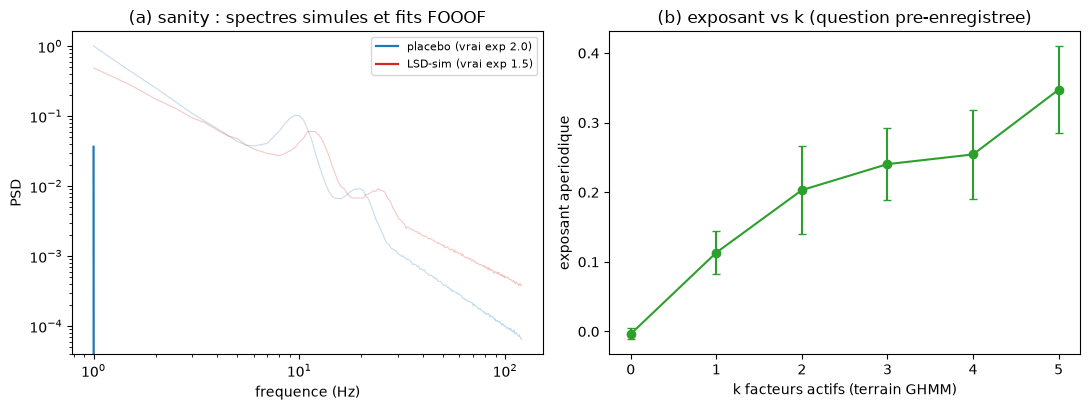

In [7]:
# Deux panneaux : (a) la sante du fit, (b) la reponse a la question pre-enregistree
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 4.2))

# --- (a) un spectre simule par condition, et le fit FOOOF en surimpression ---
rng = np.random.default_rng(0)
for name, color in (("pbo", "tab:blue"), ("lsd", "tab:red")):
    psd = make_psd(COND[name], rng)
    fm = fit_spec(psd)
    # Trait fin et translucide : le spectre simule brut
    ax1.loglog(FREQS, psd, color=color, alpha=0.25, lw=0.8)
    # Trait epais : le spectre ajuste, qui doit suivre l'aperiodique et les deux pics
    ax1.loglog(FREQS, fm.fooofed_spectrum_, color=color, lw=1.6,
               label={"pbo": "placebo (vrai exp 2.0)", "lsd": "LSD-sim (vrai exp 1.5)"}[name])
ax1.set_xlabel("frequence (Hz)")
ax1.set_ylabel("PSD")
ax1.set_title("(a) sanity : spectres simules et fits FOOOF")
ax1.legend(fontsize=8)

# --- (b) exposant moyen par k, barres d'erreur = dispersion inter-graines ---
ks = np.array(K_GRID)
mus = np.array([mean_by_k[k] for k in K_GRID])
stds = np.array([std_by_k[k] for k in K_GRID])
ax2.errorbar(ks, mus, yerr=stds, marker="o", color="tab:green", capsize=3)
ax2.set_xlabel("k facteurs actifs (terrain GHMM)")
ax2.set_ylabel("exposant aperiodique")
ax2.set_title("(b) exposant vs k (question pre-enregistree)")
ax2.set_xticks(K_GRID)

fig.tight_layout()
plt.show()

### Lecture du résultat

À gauche, les deux spectres simulés (trait fin) et leurs fits (trait épais) : l'œil suit les pics qui se déplacent (10 → 12 Hz, 20 → 25 Hz) et la droite apériodique qui s'aplatit (exposant 2,0 → 1,5). À droite, la réponse de l'exposant au nombre de facteurs : croissance quasi monotone dont les barres d'erreur inter-seeds sont petites devant l'étendue — le signal est la pente, pas la dispersion.


## 7. Exercices

Les trois exercices suivent la discipline de la série : stubs exécutables sans erreur (le carnet tourne de bout en bout non complété), étapes et indices en commentaire.


### Exercice 1 — la bande gamma après retrait apériodique

Le papier rapporte (H2) un gamma moyen (60–90 Hz) qui **augmente** après retrait de l'apériodique. Notre simulateur ne touche pas au gamma : une métrique **découplée** (amplitude de pic PW en log, §4) rend bien ~0 % d'écart sur cette bande — mais l'aire **linéaire**, elle, reste couplée à l'apériodique (cellule H2 : gamma **+327,9 %**, sur une bande intacte). Écris `band_contrast(band, seed)` qui retourne l'écart en % de l'aire de puissance oscillatoire pour une bande donnée (le calcul de la cellule H2, comme fonction réutilisable), vérifie gamma sur les 4 seeds, puis **explique** pourquoi l'aire linéaire produit un écart aussi grand sur une bande que le simulateur n'a pas touchée (indice : la recomposition de la composante apériodique sous le pic).


In [8]:
def band_contrast(band, seed):
    """Attenuation en % de la puissance oscillatoire d'une bande (lsd vs pbo).

    TODO etudiant
    """
    # Etape 1 : rng depuis seed, generer psd pbo et lsd avec make_psd
    # Etape 2 : ajuster les deux fit_spec, recomposer les composantes pics
    # Etape 3 : aire par bande (np.trapezoid) puis 100 * (lsd/pbo - 1)
    # Indice : la cellule H2 fait exactement ce calcul pour toutes les bandes
    print("Exercice 1 a completer")
    return None


print("gamma, metrique aire lineaire (cf cellule H2) -- attendu ~+328 % :")
for s in SEEDS:
    print("  seed", s, "->", band_contrast("gamma", s))

gamma, metrique aire lineaire (cf cellule H2) -- attendu ~+328 % :
Exercice 1 a completer
  seed 0 -> None
Exercice 1 a completer
  seed 1 -> None
Exercice 1 a completer
  seed 7 -> None
Exercice 1 a completer
  seed 42 -> None


### Exercice 2 — la zone d'aveuglement en largeur de pic

FOOOF ne peut pas détecter un pic plus étroit que la borne inférieure de `peak_width_limits` (1 Hz par défaut ici). Fais varier la largeur du pic alpha de 0,4 à 8 Hz à amplitude constante, mesure `|CF̂ − CF|`, et retourne la plus petite largeur pour laquelle l'erreur reste sous 0,5 Hz : c'est le **seuil de résolution** de l'instrument — une quantité de calibration, pas une constante du phénomène (même leçon qu'ICT-36e sur le seuil SNR).


In [9]:
def resolution_threshold(bw_grid, seed=0, tol_hz=0.5):
    """Plus petite largeur de pic alpha dont le CF est recupere a tol_hz pres.

    TODO etudiant
    """
    # Etape 1 : pour chaque bw de bw_grid, construire COND-like avec peaks=[(10.0, 1.0, bw)]
    # Etape 2 : fit_spec puis peaks_cf(fm, 1) -> erreur |CF - 10.0|
    # Etape 3 : retourner le plus petit bw dont l'erreur <= tol_hz (None si aucun)
    # Indice : spec = dict(offset=0.0, exponent=2.0, peaks=[(10.0, 1.0, bw)])
    print("Exercice 2 a completer")
    return None


bw_grid = [0.4, 0.6, 0.8, 1.0, 1.5, 2.0, 3.0, 5.0, 8.0]
print("seuil de resolution :", resolution_threshold(bw_grid))

Exercice 2 a completer
seuil de resolution : None


### Exercice 3 — le pont HFD × exposant spectral

ICT-36c a mesuré que la HFD (antropy, Kmax = 18) **décroît** avec k (2,00 → 1,93). Ce carnet mesure l'exposant spectral. Sur le même k-grid, calcule la HFD moyenne par terrain (échantillonne 4 canaux × 2 prompts pour le coût, Kmax = 18) et la corrélation de Spearman entre HFD et exposant à travers les 24 terrains : les deux témoins — temporel et spectral — répondent-ils **en sens opposés** à k, comme les verdicts 36c et ce carnet le laissent prévoir ?


In [10]:
def hfd_vs_exponent(n_channels=4, n_prompts=2, kmax=18):
    """HFD moyenne et exposant pour chaque terrain du k-grid, puis Spearman.

    TODO etudiant
    """
    # Etape 1 : pour chaque (k, seed), build_terrain puis echantillonner canaux/prompts
    # Etape 2 : ent.higuchi_fd(resid[:, ch], kmax=kmax) par canal, moyenner
    # Etape 3 : apparier avec rows_k[(k, seed)]["exponent"]
    # Etape 4 : scipy.stats.spearmanr(hfd_list, exp_list) -> retourner (rho, p)
    # Indice : rows_k indexe par ordre k x seed (k externe, seed interne)
    print("Exercice 3 a completer")
    return None


hfd_vs_exponent()

Exercice 3 a completer


## 8. Limites et suite

- **Terrain simulé, vérité exacte — aucune donnée neurale n'est touchée.** Les H1/H2 « reproduits » ici le sont **sur le simulateur**, pas sur le MEG du papier : ils valident l'instrument, pas le phénomène. Les données MEG des 17 participants de Subramani et al. ne sont pas publiques (« Queries regarding data are to be directed to SM and RC-H », §8 du papier) — la jambe sur données réelles reste bloquée côté demande aux auteurs (question inscrite au registre utilisateur).
- **Le papier et son code restent les références** : PDF archivé dans le gisement (`G:\Mon Drive\MyIA\IA\Bibliographie IA\Consciousness\`), pipeline public `venkateshness/specparam_LSD` (BIDS → Autoreject → dSPM → Glasser 360 → specparam) — notre sanity en est la maquette spectrale, pas la réplique complète.
- **`fooof` 1.1 est déprécié** au profit de `specparam` (même auteur) ; le papier et son code utilisent FOOOF, ce carnet suit le papier. La migration specparam est un grain à part si la série en a besoin.
- **Échelle de fréquence abstraite sur le GHMM** : le « pas » du terrain n'est pas une seconde ; l'exposant du terrain (b) se lit en fréquence normalisée, comparable **entre k** mais pas au 1–120 Hz du MEG. La comparaison qui compte est la **pente vs k**, pas la valeur absolue.
- **Environnement** : kernel `ict-py313` installé localement (règle F : installer, pas contourner) — numpy/scipy/matplotlib + `fooof` 1.1 + `antropy`, aucun appel réseau.


## Verdict

Quatre questions posées, quatre verdicts — chacun **sur le simulateur** (aucune donnée neurale n'est touchée, cf. limites) :

1. **Sanity — OUI.** FOOOF récupère la vérité terrain de son propre modèle génératif : écart ≤ 0,019 sur l'exposant, ≤ 0,06 Hz sur les fréquences centrales. L'instrument est valide au régime moyenné.
2. **H1 — OUI, conditionnel.** Les décalages de pics sont récupérés sur le spectre moyen (alpha +1,98 ± 0,02 Hz, beta +5,25 ± 0,75 Hz) ; à amplitude de pic beta 0,35, l'epoch unique (bruit ×3) passe sous le plancher de l'instrument (σ : 0,75 → 8,23 Hz, signe instable). `H1_REPRODUCED` au régime du protocole papier ; le moyennage est une condition de la mesure, pas un confort.
3. **H2 — OUI, en échelle log.** La suppression d'amplitude est mesurée proprement par les PW (−48,4 % alpha / −33,2 % beta, contre −50 % / −37 % écrits) tandis que l'aire linéaire par bande **renverse le signe** (gamma +328 % sur une bande intacte). `H2_REPRODUCED` avec la métrique log ; l'aire de bande n'est pas une mesure « genuine ».
4. **Question k — OUI, prédiction confirmée.** L'exposant apériodique croît avec k (+4,7 σ k5-vs-k1, pente +0,063/facteur) : premier compteur croissant de la série après quatre instruments décroissants — mesuré à SNR par canal croissant avec k dans ce montage (chaque facteur ajouté dépose aussi de l'énergie), pas à SNR contrôlé. Pont : un aplatissement spectral signale *moins* de structure factorielle persistante — cohérent avec ICT-36d, pas avec un recrutement de facteurs.


## À retenir

- Le carnet monte l'instrument spectral du papier LSD — la **paramétrisation FOOOF** (apériodique 1/f + pics gaussiens, 1–120 Hz, au plus 5 pics) — et le **sanity-check** sur des spectres simulés à vérité exacte : exposants 2,019 / 1,510 (vrais 2,00 / 1,50), fréquences centrales 10,06 / 20,06 / 12,01 / 24,96 Hz (écart ≤ 0,06 Hz).
- **H1 récupérée** : les décalages de fréquence pic du papier sont mesurés par l'instrument — alpha **+1,98 ± 0,02 Hz** (vrai +2,0), beta **+5,25 ± 0,75 Hz** (vrai +5,0) sur le spectre moyen.
- **H2 et le piège de l'aire** : la métrique naïve (aire linéaire) **renverse le verdict** — theta +14,1 %, alpha +52,8 %, beta +109,6 %, gamma +327,9 % — alors que le simulateur n'abaisse que des amplitudes de pics et qu'il n'y a **aucun pic en gamma** ; la suppression « genuine » ne se lit qu'avec une métrique **découplée de l'apériodique** (amplitude de pic PW en log).
- **La question de la série, tranchée** : l'exposant apériodique **croît** avec le nombre de facteurs k, de −0,004 (k = 0, bruit pur — le zéro absolu) à **0,347** (k = 5), quasi monotone, **+4,7 σ** entre k1 et k5 — le **seul** des cinq instruments de la série qui croît avec k (PR, NC@95, HFD, LZC décroissent tous).
- **Périmètre honnête** : terrain simulé, vérité exacte — **aucune donnée neurale touchée** ; H1/H2 sont « reproduites » **sur le simulateur**, ce qui valide l'instrument, pas le phénomène.

## Vérifiez votre compréhension

1. **Pourquoi la métrique d'aire linéaire renverse-t-elle le verdict H2 ?**
<details><summary>Réponse</summary>
Parce qu'elle est **couplée à l'apériodique** : un spectre dont la pente 1/f s'aplatit perd de la puissance partout, bandes confondues, et l'aire totale ne distingue plus « suppression d'un pic » de « changement de la composante apériodique ». Le simulateur n'abaisse que des amplitudes de pics et n'a aucun pic en gamma, pourtant l'aire linéaire annonce gamma +327,9 % : c'est l'apériodique qui parle. La métrique PW en log, calculée sur l'amplitude de pic **après** retrait de l'apériodique, est découplée par construction.
</details>

2. **Pourquoi k = 0 (bruit pur) est-il le « zéro absolu » de l'exposant ?**
<details><summary>Réponse</summary>
Parce qu'un bruit pur a un spectre **plat** : aucune composante 1/f, donc un exposant apériodique théorique nul. La mesure (−0,004 ± 0,008) cale l'origine de l'échelle — c'est ce qui rend lisible la croissance quasi monotone jusqu'à 0,347 à k = 5 : l'exposant compte réellement les facteurs latents, au lieu de partir d'un niveau arbitraire.
</details>

3. **Pourquoi l'exposant apériodique est-il le cinquième — et inverse — instrument de la série ?**
<details><summary>Réponse</summary>
ICT-36c a tranché par la mesure que les quatre instruments jusqu'ici (PR, NC@95, HFD, LZC) **décroissent** tous quand k augmente. L'exposant spectral, mesuré ici sur le même terrain GHMM redéfini fidèlement, **croît** avec k : c'est le seul instrument qui suit le nombre de facteurs dans le sens « plus de facteurs = plus de valeur », ce qui en fait le candidat naturel pour lire une hausse du type de celle rapportée par le papier LSD.
</details>

## Pour aller plus loin

- **Carnets précédents** : [ICT-36c](ICT-36c-FLens-HiguchiBridge-Python.ipynb) (le pont F-Lens × Higuchi et la question « quel instrument suit k ? »), [ICT-36d](ICT-36d-FLens-DecorrelationTemporelle-Python.ipynb) (ce qu'une HFD qui monte veut vraiment dire), [ICT-36e](ICT-36e-FLens-SNR-Python.ipynb) (le plancher de bruit de la géométrie factorielle).
- **Le papier** : Subramani et al. 2026, *LSD Reconfigures Cortical Dynamics Through Faster Brain Rhythms and Increased Fractal Dimension* (bioRxiv 10.64898/2026.01.28.702361) — dépôt de distillation [#20463](https://github.com/jsboige/CoursIA/issues/20463).
- **Suite naturelle** : le test d'additivité multi-domain du papier (décodage Random Forest single-domain vs multi-domain, livré sur ce grain par #26118) ; et, côté F-Lens, la question miroir — l'exposant apériodique du **residual stream** d'un LLM suit-il ses facteurs latents ? Même instrument, autre terrain : c'est le croisement exact que le pont de 36c appelait.